## Script to process multiple years to find the winter like and summer like days from NASA NEX-GDP-CMIP6 models

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import warnings
warnings.filterwarnings('ignore')



In [2]:
###################
# helper functions
###################
def WinterSummerDays(temp_data, temp_data_next, winter_threshold, summer_threshold, show_plot):
    '''

    Function that uses the input 25th and 75th percentile temperature in K to identify summer-like and winter-like days and Tmin day from a time series of temperatures.
    Input data should already be set to 365 days.

    Args:
        temp_data: xarray of temperature data for a single grid cell for the year of interest
        temp_data_next: xarray of temperature data for a single grid cell for the following year (for NH winters, SH summers)
        winter_threshold: xarray for the 25th percentile threshold to use
        summer_threshold: xarray for the 75th percentile threshold to use
        show_plots: boolean for whether to plot the summer and winter time series with the labeled WLD and SLD, max and min
        
    Returns:
        first WLD: first DOY that daily mean t2m is below winter threshold (25th percentile)"
        last WLD: last DOY that daily mean t2m is below winter threshold (25th percentile)
        first SLD: first DOY that daily mean t2m is above summer threshold (75th percentile)
        last SLD: last DOY that daily mean t2m is above summer threshold (75th percentile)
        winterlike days: number of days in the 12 month period that had a mean T2m <= the winter threshold
        summerlike days: number of days in the 12 month period that had a mean T2m >= the summer threshold
        
    Example:
        first_wld, last_wld, first_sld, last_sld, winterlike_days, summerlike_days = WinterSummerDays(temps, temps_next, winter_threshold, summer_threshold, True)

    '''

    # default values
    first_wld = 0 
    last_wld = 0
    first_sld = 0 
    last_sld = 0
    winter_like_days = 0
    summer_like_days = 0

    # split method based on NH or SH
    # WLD should be counted and indexed over the cycle with winter at the center to see trends over time
    # otherwise the first WLD will nearly always be day 1 of the year in the NH 
    # similarly for SLD in the SH we want the summer months of DJF to be in the center of the cycle

    # extract DOY and T2m values for those days from just the current year
    x1_cur = temp_data.time.dt.dayofyear.values
    y1_cur = temp_data.values

    # same but for current plus next for SH summer and NH winter
    ds_two = xr.concat([temp_data, temp_data_next], dim="time")

    # get the current year for slicing
    input_year = temp_data.time.dt.year.values[0]

    # select July 1 - June 30 across the two years to do fit
    startdate = str(input_year)+'-07-01' # 182nd day of a normal year
    enddate = str(input_year+1)+'-06-30'
    offset_yr = ds_two.sel(time=slice(startdate,enddate))
    
    # DOY (relative to July 1) and T2m values for those days
    x1_off = np.arange(1,len(offset_yr.time)+1) 
    y1_off = offset_yr.values

    ######
    # Southern Hemisphere 
    ######
    if temp_data.lat.values < 0:
        ########
        # Winter uses current year only

        # count of winter-like days in the year (any time during the year)
        # and the first/last occurence where the winter months (JJA) are centered in the cycle
        winter_like_days = np.where(y1_cur <= winter_threshold.values)[0].size

        # handle the case where NO days are below the threshold for winter
        if winter_like_days > 0:
            first_wld = np.where(y1_cur <= winter_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_wld = np.where(y1_cur <= winter_threshold.values)[0][-1] + 1

        ########
        # Summer uses current year and next year

        # count of summer-like days in the year (any time during the "year)"
        # and the first/last occurence where the summer months (DJF) are centered in the cycle
        summer_like_days = np.where(y1_off >= summer_threshold.values)[0].size

        # handle the case where no days are above summer threshold (seems unlikely but just in case)
        if summer_like_days > 0:
            first_sld = np.where(y1_off >= summer_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_sld = np.where(y1_off >= summer_threshold.values)[0][-1] + 1

        if show_plot:
            fs = 8
            cell_lat = temp_data.lat.values
            cell_lon = temp_data.lon.values
            yr = temp_data.time.dt.year.values[0]
            
            fig = plt.figure(figsize=(16,5), layout='constrained')
            # SH winter
            ax1 = fig.add_subplot(1,2,1)
            ax1.plot(x1_cur,y1_cur, label='daily mean T2m')
            ax1.axhline(winter_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax1.annotate('first WLD', xy=(first_wld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('last WLD', xy=(last_wld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('25th percentile = '+str(np.round(winter_threshold.values[0],1))+'K', xy=(0,winter_threshold.values[0]+1), fontsize=fs+2)
            ax1.set_xlabel('DOY (' + str(yr) + ')')
            ax1.set_ylabel('Mean Daily Temp (K)')
            ax1.set_title(str(yr) + " Winter for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")

            # SH Summer
            ax2 = fig.add_subplot(1,2,2)
            ax2.plot(x1_off,y1_off, label='daily mean T2m')
            ax2.axhline(summer_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax2.annotate('first SLD', xy=(first_sld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('last SLD', xy=(last_sld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('75th percentile = '+str(np.round(summer_threshold.values[0],1))+'K', xy=(0,summer_threshold.values[0]+1), fontsize=fs+2)
            ax2.set_xlabel('DOY (' + str(yr) + ') relative to July 1')
            ax2.set_ylabel('Mean Daily Temp (K)')
            ax2.set_title(str(yr) + " Summer for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")
            plt.show()
    
    ######
    # Northern Hemisphere 
    # winter uses current year and following year
    else: 

        # Winter
        # count of winter-like days in the year (any time during the year)
        # and the first/last occurence where the winter months (DJF) are centered in the cycle
        winter_like_days = np.where(y1_off <= winter_threshold.values)[0].size

        # handle the case where NO days are below the threshold for winter
        if winter_like_days > 0:
            first_wld = np.where(y1_off <= winter_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_wld = np.where(y1_off <= winter_threshold.values)[0][-1] + 1

        # Summer       
        # count of summer-like days in the year (any time during the year)
        # and the first/last occurence where the summer months (JJA) are centered in the cycle
        summer_like_days = np.where(y1_cur >= summer_threshold.values)[0].size

        # handle the case where no days are above summer threshold (seems unlikely but just in case)
        if summer_like_days > 0:
            first_sld = np.where(y1_cur >= summer_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_sld = np.where(y1_cur >= summer_threshold.values)[0][-1] + 1
                
        if show_plot:
            fs = 8
            cell_lat = temp_data.lat.values
            cell_lon = temp_data.lon.values
            yr = temp_data.time.dt.year.values[0]
            
            fig = plt.figure(figsize=(16,5), layout='constrained')
            # NH Winter
            ax1 = fig.add_subplot(1,2,1)
            ax1.plot(x1_off,y1_off, label='daily mean T2m')
            ax1.axhline(winter_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax1.annotate('first WLD', xy=(first_wld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('last WLD', xy=(last_wld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('25th percentile = '+str(np.round(winter_threshold.values[0],1))+'K', xy=(0,winter_threshold.values[0]+1), fontsize=fs+2)
            ax1.set_xlabel('DOY (' + str(yr) + ') relative to July 1')
            ax1.set_ylabel('Mean Daily Temp (K)')
            ax1.set_title(str(yr) + " Winter for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")

            # NH Summer
            ax2 = fig.add_subplot(1,2,2)
            ax2.plot(x1_cur,y1_cur, label='daily mean T2m')
            ax2.axhline(summer_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax2.annotate('first SLD', xy=(first_sld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('last SLD', xy=(last_sld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('75th percentile = '+str(np.round(summer_threshold.values[0],1))+'K', xy=(0,summer_threshold.values[0]+1), fontsize=fs+2)
            ax2.set_xlabel('DOY (' + str(yr) + ')')
            ax2.set_ylabel('Mean Daily Temp (K)')
            ax2.set_title(str(yr) + " Summer for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")
            plt.show()       
    
    # return
    return int(first_wld), int(last_wld), int(first_sld), int(last_sld), int(winter_like_days), int(summer_like_days)
    




In [3]:
# a function that takes in a dataset of global t2m values and if it is a leap year averages
# the temps on Feb 28 & Feb 29, then drops Feb 29 to ensure the year has 365 days
def HandleLeapYears(input_ds):
    '''

    Function that takes the mean of Feb 28 & Feb 29 (if it exists) and returns an xarray Dataset that has 365 days
    where Feb 28 will now have a tas value that is the mean of Feb 28 & Feb 29

    Args:
        input_ds: the data set containing a single year of data that may need adjusting for leap year
        
    Returns:
        output_ds
        
    Example:
        no_leap_ds = HandleLeapYears(input_ds)

    '''
    

    # check if a leap year
    if(input_ds.time.dt.is_leap_year[0].values):
        
        # make deep copy
        output_ds = input_ds.copy(deep=True)
        
        # get mean of Feb 28 (time index 58) & Feb 29 (time index 59) for each grid cell and overwrite Feb 28 with it
        mean_dat = output_ds.tas[58:60].mean(dim='time', skipna=True, keep_attrs=True)
        output_ds.tas[58] = mean_dat
        
        # drop Feb 29
        output_ds = output_ds.convert_calendar('noleap', use_cftime=None)

        # ensure time is datetime64
        output_ds["time"] = output_ds.time.dt.strftime('%Y-%m-%d')
        output_ds['time'] = pd.to_datetime(output_ds['time'])

        # return the new dataset 
        return output_ds
    else:
        return input_ds
    

## Test one model to verify algorithm

In [7]:
%%time

input_year = 2000

md = 'ACCESS-ESM1-5'

# summer thresh
file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_75th.nc'
c_75 = xr.open_dataarray(file_path1)

# winter thresh
file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_25th.nc'
c_25 = xr.open_dataarray(file_path2)


file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_historical_'+str(input_year)+'.nc'
dsnow = xr.open_mfdataset(file_path1)
dsnow = HandleLeapYears(dsnow)
dsnow.load()

file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_historical_'+str(input_year+1)+'.nc'
dsnext = xr.open_mfdataset(file_path2)
dsnext = HandleLeapYears(dsnext)
dsnext.load()



CPU times: user 7.29 s, sys: 1.86 s, total: 9.15 s
Wall time: 9.26 s


<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2001-01-01T12:00:00 ... 2001-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes: (12/24)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    activity:              NEX-GDDP-CMIP6
    frequency:             day
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sat Nov 16 20:03:19 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           6befcae6-42f3-4da8-a7d3-fae381ac99e1
    history:               Sun Oct 11 18:41:00 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

In [8]:
#test for Vancouver
input_lat = 49.246
input_lon = -123.116

summer_thresh = c_75.sel(lat=input_lat, lon=input_lon, method="nearest")
winter_thresh = c_25.sel(lat=input_lat, lon=input_lon, method="nearest")
summer_thresh.values, winter_thresh.values

(array([287.15677], dtype=float32), array([278.6815], dtype=float32))

In [9]:

curr = dsnow.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 array([275.33994, 271.04102, 273.3056 , 275.78555, 278.21832, 276.6828 ,
        276.33716, 276.13235, 271.00488, 270.83765, 274.25122, 272.34967,
        268.86182, 271.99823, 270.8439 , 271.61676, 272.80054, 272.20493,
        263.199  , 271.89227, 280.024  , 281.1007 , 280.2227 , 276.47214,
        271.67017, 275.3034 , 277.9519 , 274.19504, 268.72488, 272.8947 ,
        269.12762, 271.9054 , 271.63788, 275.72412, 275.58698, 274.96426,
        277.88934, 278.9095 , 276.76212, 273.42834, 275.03226, 278.20486,
        280.5676 , 278.53436, 277.7524 , 278.72345, 280.27197, 279.05444,
        269.19116, 265.2956 , 264.7537 , 264.0978 , 267.8899 , 268.77252,
        264.41187, 261.63217, 263.2146 , 266.64374, 270.98077, 275.16522,
        275.95743, 279.2059 , 278.7951 , 275.18268, 277.70615, 275.06155,
        279.81018, 281.21198, 278.1291 , 281.23834, 278.56885, 279.8837 ,
        280.8287 , 277.7079 , 277.46143, 279.7582 , 280.9015 , 2

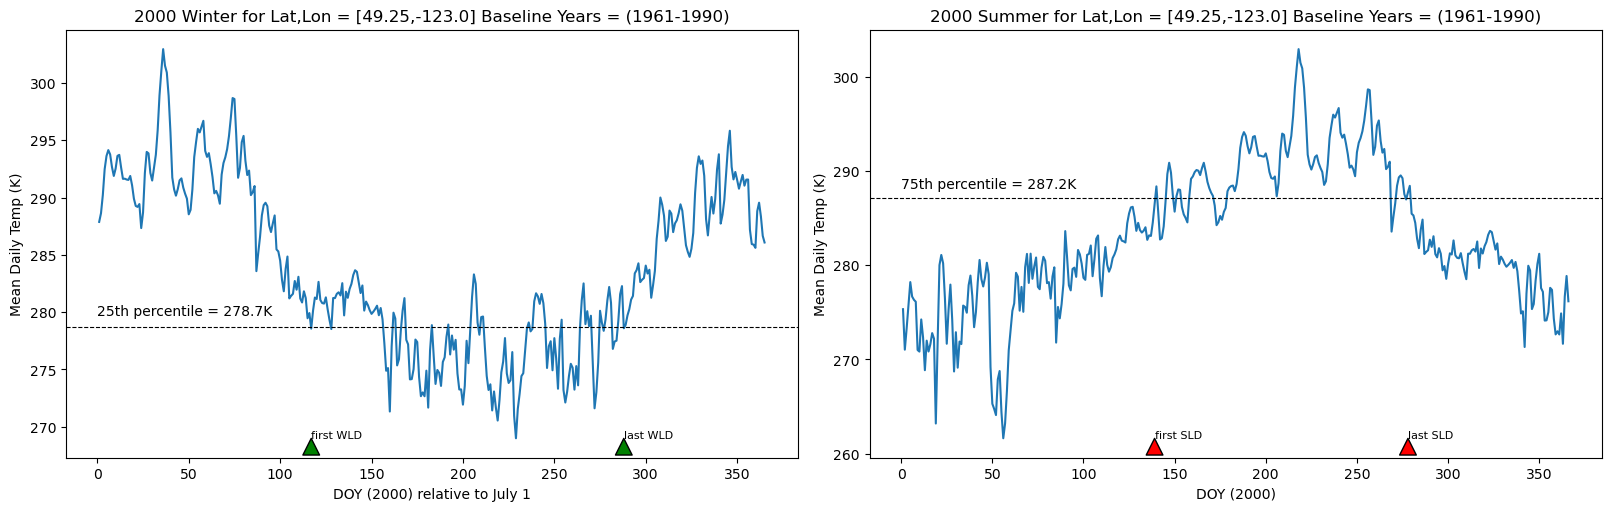

(117, 288, 139, 278, 98, 119)

In [14]:
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, True)
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays

In [15]:
# Sydney
input_lat = -33 - 52/60 - 4/3600
input_lon = 151.25

summer_thresh = c_75.sel(lat=input_lat, lon=input_lon, method="nearest")
winter_thresh = c_25.sel(lat=input_lat, lon=input_lon, method="nearest")
summer_thresh.values, winter_thresh.values

(array([294.0272], dtype=float32), array([286.9937], dtype=float32))

In [16]:
curr = dsnow.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 array([296.56473, 297.13364, 298.27448, 298.00473, 297.35062, 293.3232 ,
        294.8689 , 297.2876 , 298.49713, 296.65448, 293.59155, 293.55032,
        293.8341 , 294.2483 , 295.5652 , 297.2791 , 293.8012 , 294.3839 ,
        294.32886, 294.908  , 295.4951 , 297.51483, 296.005  , 292.548  ,
        292.8067 , 294.2765 , 295.55865, 295.9864 , 295.80637, 296.127  ,
        297.23706, 297.25873, 293.87964, 293.96173, 295.945  , 297.1549 ,
        297.69592, 296.0832 , 295.00085, 294.02716, 292.3463 , 292.67355,
        293.1933 , 293.38873, 294.7844 , 295.7461 , 295.43384, 296.45947,
        297.2735 , 298.75922, 299.62128, 298.1114 , 295.84155, 295.28067,
        294.9389 , 296.07126, 297.47073, 299.25662, 299.00177, 298.3205 ,
        299.7905 , 300.52618, 296.73914, 295.86768, 295.5797 , 296.41806,
        297.60022, 297.1297 , 293.3324 , 293.90903, 294.25708, 294.90472,
        294.68604, 295.16895, 294.51486, 295.5011 , 295.93674, 2

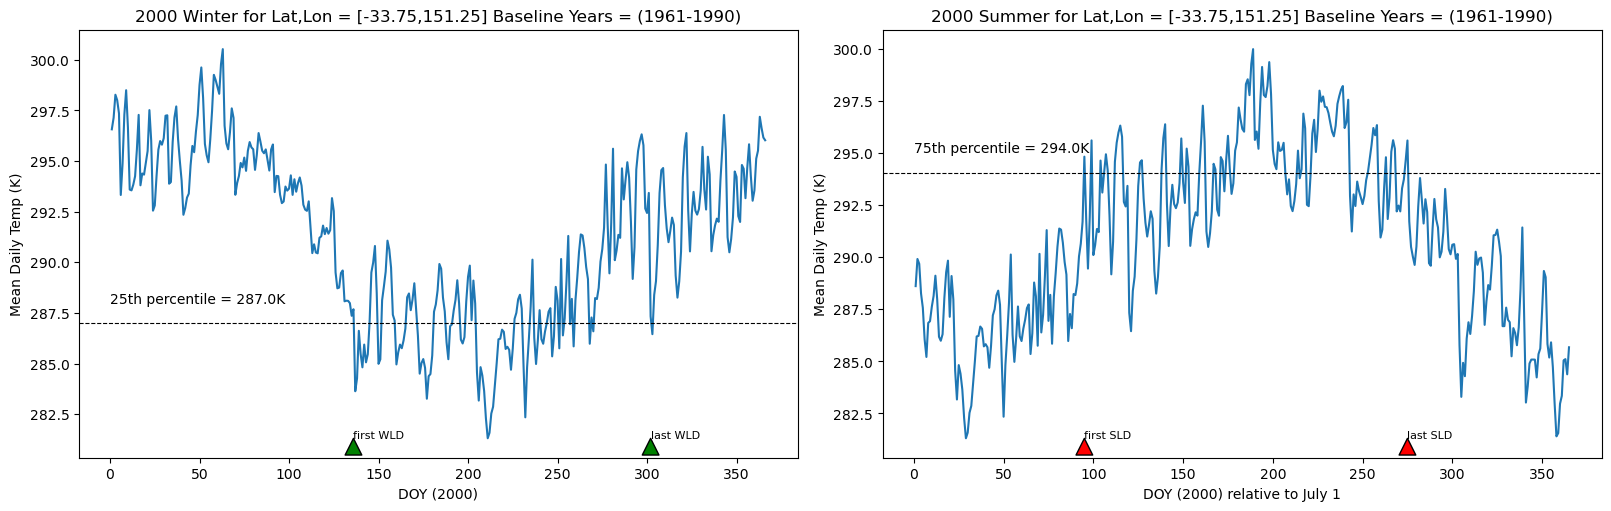

(136, 302, 95, 275, 72, 94)

In [19]:
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, True)
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays

#### Looks to be working for Vancouver and Sydney

In [6]:
file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/MPI-ESM1-2-HR/regridded/tas_MPI-ESM1-2-HR_ssp245_2090.nc'
test = xr.open_dataset(file_path1)
test

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2090-01-01T12:00:00 ... 2090-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB ...
Attributes: (12/24)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    activity:              NEX-GDDP-CMIP6
    frequency:             day
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sun Nov 17 03:00:50 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           7c9c73fd-197a-4d79-90cb-b6a534b85359
    history:               Sun Nov 08 12:44:33 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

## Process all years and experiments for set of models

In [4]:
%%time

# XX min per year
# roughly XX hrs per model

# comment out as needed
models = [#'ACCESS-ESM1-5',
    #'BCC-CSM2-MR',
    #'CMCC-ESM2',
    #'FGOALS-g3',
    #'GFDL-ESM4',
    #'GISS-E2-1-G',
    #'MIROC-ES2L',
    #'MIROC6',
    'MPI-ESM1-2-HR',
    #'MRI-ESM2-0',
    #'NorESM2-LM'
]

# run through the list of models
for md in models:

    start = dt.now()

    # summer thresh
    file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_75th.nc'
    c_75 = xr.open_dataarray(file_path1)

    # winter thresh
    file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_25th.nc'
    c_25 = xr.open_dataarray(file_path2)

    # grid parameters for looping
    num_lat = c_75.lat.shape[0]
    num_lon = c_75.lon.shape[0]
    loop_lats = c_75.lat.values[:num_lat]
    loop_lons = c_75.lon.values[:num_lon]

    ######
    # Historical period
    process_yrs = np.arange(1961, 2015,1) 
    
    # loop thru the years in the defined array above
    for input_year in process_yrs:
    
        start_yr = dt.now()

        # don't need to load in current year if we've already loaded it
        if input_year == 1961:
            # read in current year and next year
            # load into memory to speed up the processing and handle leap years to be 365 days
            file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_historical_'+str(input_year)+'.nc'
            dsnow = xr.open_mfdataset(file_path1)
            dsnow = HandleLeapYears(dsnow)
            dsnow.load()
        else:
            dsnow = dsnext

        # Note: to process 2014 we need 2015 for SH summer so using ssp245 2015 for that one added year
        if input_year < 2014:
            file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_historical_'+str(input_year+1)+'.nc'
        else:
            file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_2015.nc'
        dsnext = xr.open_mfdataset(file_path2)
        dsnext = HandleLeapYears(dsnext)
        dsnext.load()
    
        # empty data arrays for stats
        first_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                    coords=[loop_lats, loop_lons], 
                                    dims=['lat','lon'])
        last_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                   coords=[loop_lats, loop_lons], 
                                   dims=['lat','lon'])
        first_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        last_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        winterlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        summerlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        
        # add attributes
        first_wld.attrs["long_name"] = "First day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        last_wld.attrs["long_name"] = "Last day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        first_sld.attrs["long_name"] = "First day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        last_sld.attrs["long_name"] = "Last day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        winterlike_days.attrs["long_name"] = "Number of days during the year where winter is centered with mean T2m at or below threshold"
        winterlike_days.attrs["units"] = "Days"
        
        summerlike_days.attrs["long_name"] = "Number of days during the year where summer is centered with mean T2m at or above threshold"
        summerlike_days.attrs["units"] = "Days"

        # loop through all of the lat,lon of interest
        for input_lat in loop_lats:
            for input_lon in loop_lons:
                # get thresholds from c_25 and c_75
                winter_thresh = c_25.sel(lat=input_lat,lon=input_lon)
                summer_thresh = c_75.sel(lat=input_lat,lon=input_lon)
    
                # if winter_thresh is nan this cell is not on land and/or outside lat range of data so skip it and set all metrics to nan
                if(np.isnan(winter_thresh[0])):
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan 
                    
                else:
                    # all the temps for that grid cell over time for this year and next (for SH)
                    curr = dsnow.tas.sel(lat=input_lat,lon=input_lon) 
                    nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)

                    # build winter stats for the grid cell and produce the plot if desired (currently False)
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, False)

                # xarray requires strange indexing in order to replace values by coordinate
                first_wld.loc[input_lat, input_lon] = firstwld
                last_wld.loc[input_lat, input_lon] = lastwld
                first_sld.loc[input_lat, input_lon] = firstsld
                last_sld.loc[input_lat, input_lon] = lastsld
                winterlike_days.loc[input_lat, input_lon] = winterlikedays
                summerlike_days.loc[input_lat, input_lon] = summerlikedays

        # save it out
        sum_ds = xr.Dataset(data_vars={'FirstWLD':first_wld,
                               'LastWLD':last_wld,
                                   'FirstSLD':first_sld,
                               'LastSLD':last_sld,
                                   'WinterlikeDays':winterlike_days,
                                   'SummerlikeDays':summerlike_days})    

        output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(input_year)+'_'+md+'_historical_summer_winter_days.nc'
        sum_ds.to_netcdf(output_path)

        end_yr = dt.now()
        elapsed = (end_yr-start_yr).total_seconds()/60.0
        print("Time for "+str(input_year)+" :"+str(elapsed)+" min")


    ######
    # SSP2-4.5 Scenario
    # can only go up through 2099 since we use 2100 for the 2099 SH summer and don't have 2101 for the 2100 SH summer
    process_yrs = np.arange(2015, 2100,1)

    # loop thru the years in the defined array above
    for input_year in process_yrs:
    
        start_yr = dt.now()

        # read in current year and next year
        # don't need to load in current year if we've already loaded it as the next year
        if input_year == 2015:
            # load into memory to speed up the processing and handle leap years to be 365 days
            file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_'+str(input_year)+'.nc'
            dsnow = xr.open_mfdataset(file_path1)
            dsnow = HandleLeapYears(dsnow)
            dsnow.load()
        else:
            dsnow = dsnext

        # Note: can't get SH summer for 2100 since we'd need 2101
        file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_'+str(input_year+1)+'.nc'
        dsnext = xr.open_mfdataset(file_path2)
        dsnext = HandleLeapYears(dsnext)
        dsnext.load()
    
        # empty data arrays for stats
        first_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                    coords=[loop_lats, loop_lons], 
                                    dims=['lat','lon'])
        last_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                   coords=[loop_lats, loop_lons], 
                                   dims=['lat','lon'])
        first_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        last_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        winterlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        summerlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        
        # add attributes
        first_wld.attrs["long_name"] = "First day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        last_wld.attrs["long_name"] = "Last day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        first_sld.attrs["long_name"] = "First day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        last_sld.attrs["long_name"] = "Last day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        winterlike_days.attrs["long_name"] = "Number of days during the year where winter is centered with mean T2m at or below threshold"
        winterlike_days.attrs["units"] = "Days"
        
        summerlike_days.attrs["long_name"] = "Number of days during the year where summer is centered with mean T2m at or above threshold"
        summerlike_days.attrs["units"] = "Days"

        # loop through all of the lat,lon of interest
        for input_lat in loop_lats:
            for input_lon in loop_lons:
                # get thresholds from c_25 and c_75
                winter_thresh = c_25.sel(lat=input_lat,lon=input_lon)
                summer_thresh = c_75.sel(lat=input_lat,lon=input_lon)
    
                # if winter_thresh is nan this cell is not on land and/or outside lat range of data so skip it and set all metrics to nan
                if(np.isnan(winter_thresh[0])):
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan 
                    
                else:
                    # all the temps for that grid cell over time for this year and next (for SH)
                    curr = dsnow.tas.sel(lat=input_lat,lon=input_lon) 
                    nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)

                    # build winter stats for the grid cell and produce the plot if desired (currently False)
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, False)

                # xarray requires strange indexing in order to replace values by coordinate
                first_wld.loc[input_lat, input_lon] = firstwld
                last_wld.loc[input_lat, input_lon] = lastwld
                first_sld.loc[input_lat, input_lon] = firstsld
                last_sld.loc[input_lat, input_lon] = lastsld
                winterlike_days.loc[input_lat, input_lon] = winterlikedays
                summerlike_days.loc[input_lat, input_lon] = summerlikedays

        # save it out
        sum_ds = xr.Dataset(data_vars={'FirstWLD':first_wld,
                               'LastWLD':last_wld,
                                   'FirstSLD':first_sld,
                               'LastSLD':last_sld,
                                   'WinterlikeDays':winterlike_days,
                                   'SummerlikeDays':summerlike_days}) 

        output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(input_year)+'_'+md+'_ssp245_summer_winter_days.nc'
        sum_ds.to_netcdf(output_path)

        end_yr = dt.now()
        elapsed = (end_yr-start_yr).total_seconds()/60.0
        print("Time for "+str(input_year)+" :"+str(elapsed)+" min")

    ######
    # SSP3-7.0
    process_yrs = np.arange(2015, 2100,1)

    # loop thru the years in the defined array above
    for input_year in process_yrs:
    
        start_yr = dt.now()

        # read in current year and next year
        # don't need to load in current year if we've already loaded it as the next year
        if input_year == 2015:
            # load into memory to speed up the summer stats processing and handle leap years to be 365 days
            file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp370_'+str(input_year)+'.nc'
            dsnow = xr.open_mfdataset(file_path1)
            dsnow = HandleLeapYears(dsnow)
            dsnow.load()
        else:
            dsnow = dsnext

        # Note: can't get SH summer for 2100 since we'd need 2101
        file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp370_'+str(input_year+1)+'.nc'
        dsnext = xr.open_mfdataset(file_path2)
        dsnext = HandleLeapYears(dsnext)
        dsnext.load()
    
        # empty data arrays for stats
        first_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                    coords=[loop_lats, loop_lons], 
                                    dims=['lat','lon'])
        last_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                   coords=[loop_lats, loop_lons], 
                                   dims=['lat','lon'])
        first_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        last_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        winterlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        summerlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        
        # add attributes
        first_wld.attrs["long_name"] = "First day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        last_wld.attrs["long_name"] = "Last day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        first_sld.attrs["long_name"] = "First day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        last_sld.attrs["long_name"] = "Last day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        winterlike_days.attrs["long_name"] = "Number of days during the year where winter is centered with mean T2m at or below threshold"
        winterlike_days.attrs["units"] = "Days"
        
        summerlike_days.attrs["long_name"] = "Number of days during the year where summer is centered with mean T2m at or above threshold"
        summerlike_days.attrs["units"] = "Days"

        # loop through all of the lat,lon of interest
        for input_lat in loop_lats:
            for input_lon in loop_lons:
                # get thresholds from c_25 and c_75
                winter_thresh = c_25.sel(lat=input_lat,lon=input_lon)
                summer_thresh = c_75.sel(lat=input_lat,lon=input_lon)
    
                # if winter_thresh is nan this cell is not on land and/or outside lat range of data so skip it and set all metrics to nan
                if(np.isnan(winter_thresh[0])):
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan 
                    
                else:
                    # all the temps for that grid cell over time for this year and next (for SH)
                    curr = dsnow.tas.sel(lat=input_lat,lon=input_lon) 
                    nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)

                    # build winter stats for the grid cell and produce the plot if desired (currently False)
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, False)

                # xarray requires strange indexing in order to replace values by coordinate
                first_wld.loc[input_lat, input_lon] = firstwld
                last_wld.loc[input_lat, input_lon] = lastwld
                first_sld.loc[input_lat, input_lon] = firstsld
                last_sld.loc[input_lat, input_lon] = lastsld
                winterlike_days.loc[input_lat, input_lon] = winterlikedays
                summerlike_days.loc[input_lat, input_lon] = summerlikedays

        # save it out
        sum_ds = xr.Dataset(data_vars={'FirstWLD':first_wld,
                               'LastWLD':last_wld,
                                   'FirstSLD':first_sld,
                               'LastSLD':last_sld,
                                   'WinterlikeDays':winterlike_days,
                                   'SummerlikeDays':summerlike_days}) 

        output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(input_year)+'_'+md+'_ssp370_summer_winter_days.nc'
        sum_ds.to_netcdf(output_path)

        end_yr = dt.now()
        elapsed = (end_yr-start_yr).total_seconds()/60.0
        print("Time for "+str(input_year)+" :"+str(elapsed)+" min")


    
    ######
    # SSP1-2.6
    
    # total time for the Model being processed
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+md+" :"+str(elapsed)+" min")

Time for 2068 :17.996046583333335 min
Time for 2069 :17.90879688333333 min
Time for 2070 :17.940966616666667 min
Time for 2071 :19.141832583333333 min
Time for 2072 :17.245024249999997 min
Time for 2073 :18.983347716666668 min
Time for 2074 :17.182632650000002 min
Time for 2075 :19.986029316666666 min
Time for 2076 :19.180829300000003 min
Time for 2077 :19.111518616666668 min
Time for 2078 :18.956045016666668 min
Time for 2079 :19.120252533333332 min
Time for 2080 :17.267399566666665 min
Time for 2081 :19.25326235 min
Time for 2082 :17.148469499999997 min
Time for 2083 :19.1428214 min
Time for 2084 :19.628357349999998 min
Time for 2085 :18.937768600000002 min
Time for 2086 :18.702621150000002 min
Time for 2087 :17.538653016666668 min
Time for 2088 :17.758934466666666 min
Time for 2089 :19.409373916666667 min
Time for 2090 :19.059868583333333 min
Time for 2091 :19.32954965 min
Time for 2092 :17.268127983333333 min
Time for 2093 :17.13768975 min
Time for 2094 :16.852623400000002 min
Time

### Inspect results from ssp370

In [5]:
sum_ds

<xarray.Dataset> Size: 50MB
Dimensions:         (lat: 721, lon: 1440)
Coordinates:
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    FirstWLD        (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    LastWLD         (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    FirstSLD        (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    LastSLD         (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    WinterlikeDays  (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    SummerlikeDays  (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan

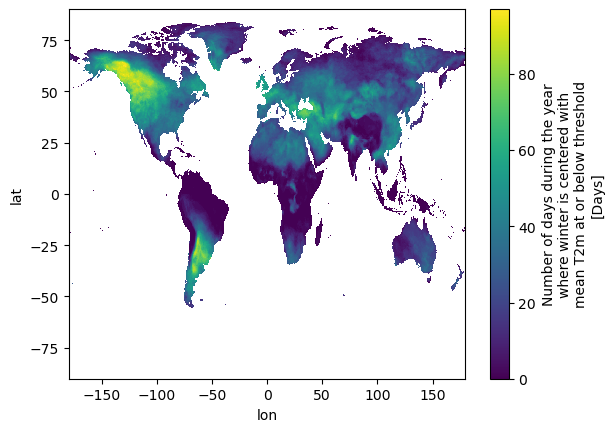

In [6]:
sum_ds.WinterlikeDays.plot()